# **Icepack tutorial: Synthetic ice shelf**  


Simulate the evolution of a floating ice shelf.  
This is an example of a *spin up*. The objective in a spin up is to obtain a physically plausible state of some system from an initial guess by simulating its evolution for a long time.  
Here, we use an idealised ice shelf geometry and a rough guuess for initial thickness. We'll solve the *diagnostic equation* for the velocity throughout the ice shelf, and then solve the *prognostic equation* to obtain ice thickness at a later time. We can solve those equations assuming ice accumulation and melting, until the system reaches a steady state.  
The simulation is divided into three parts:
1) Define the shape of the ice shelf and get a triangulation of the interior
2) Define the initial guess for the ice thickness and velocity, and set a value of the rheology and accumulation rate.
3) Set the total simulation time and number of steps, then iteratively update the ice thickness and velocity at each step.



## **Geometry**  
Inflow boundary: circular arc centered at the origin with radius = 200 km.  
Outflow boundary: Another circular arc with a much higher radius.  

For more complicated shapes a mesh generator is used. The program turns a description of the boundary of a spatial domain into a triangulation of the interior.  

First, define the mesh radius and spacing for the mesh cells:

In [1]:
import gmsh
gmsh.initialize()

R = 200e3
δx = 5e3

Next, create an empty geometry and add some points to it. *x1* and *x2* represent the left and right endpoints of the mesh. *center1* and *center2* define the centers of the two circular arcs. 

In [3]:
geometry = gmsh.model.geo

x1 = geometry.add_point(-R, 0, 0, δx)
x2 = geometry.add_point(+R, 0, 0, δx)

center1 = geometry.add_point(0, 0, 0, δx)
center2 = geometry.add_point(0, -4 * R, 0, δx)

arcs = [
    geometry.add_circle_arc(x1, center1, x2),
    geometry.add_circle_arc(x2, center2, x1)
]

Next, gmsh needs information on the topology, i.e. how all the arcs are connected to each other and how they're oriented. gmsh will tag each geometric entity with a number that we can use to set different boundary conditions.

In [4]:
line_loop = geometry.add_curve_loop(arcs)
plane_surface = geometry.add_plane_surface([line_loop])

physical_lines = [geometry.add_physical_group(1, [arc]) for arc in arcs]
physical_surface = geometry.add_physical_group(2, [plane_surface])

To get a mesh:  
1) synchronise the geometry model in order to add all its elements into an internal data structure for gmsh
2) generate the triangular mesh
3) write it out in a file.

In [5]:
geometry.synchronize()
gmsh.model.mesh.generate(2)
gmsh.write("ice-shelf.msh")
gmsh.finalize()

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Circle)
Info    : [ 60%] Meshing curve 2 (Circle)
Info    : Done meshing 1D (Wall 0.000360458s, CPU 0.000495s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0787344s, CPU 0.067996s)
Info    : 3373 nodes 6744 elements
Info    : Writing 'ice-shelf.msh'...
Info    : Done writing 'ice-shelf.msh'


This output tells us how many vertices and triangle the mesh contains, and will also report if something went wrong. Meshes don't always need to be generated - it's common to start witha digitised glacier outline in the form of a shapefile or GeoJSON file.  

To load the mesh, pass the filename to the function *firedrake.Mesh*.

In [6]:
import firedrake

mesh = firedrake.Mesh("ice-shelf.msh")

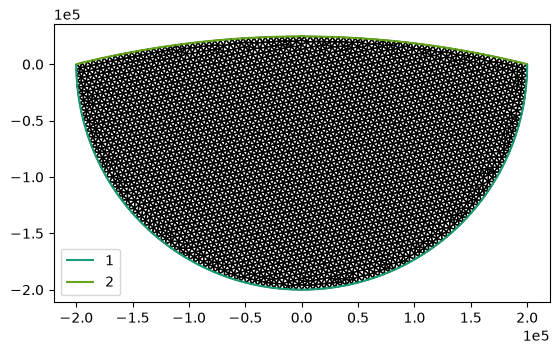

In [7]:
import icepack.plot
import matplotlib.pyplot as plt

fig, axes = icepack.plot.subplots()
firedrake.triplot(mesh, axes=axes)
axes.legend(loc="lower left");

The two boundaries are coloured to help define the Dirichlet (inflow) and Neumann (terminus) boundary conditions where they apply. 1 = inflow boundary, 2 = calving terminus.

## **Input data**  
To mimic the state of a real ice shelf, we'll pick a few angles along the inflow boundary that represent the centerlines of the ice streams that feed the shelf. We'll then define velocity and thickness profiles along the inflow boundary. We'll pick a somewhat arbitrary initial profile and evolve it towards steady state, as we don't have a great idea of what the steady state is.  

Many ice shelves have several streams feeding them. Our glacier will be fed by four streams. We'll define the inlets by picking angles around the inflow boundary where each inlet comes in, and the width, in radians. 

In [8]:
import numpy as np
from numpy import pi as π

inlet_angles = π * np.array([-3/4, -1/2, -1/3, -1/6])
inlet_widths = π * np.array([1/8, 1/12, 1/24, 1/12])

Next, we'll come up with some arbitrary and un-physical input data. The idea is to make the thickness slope down as you go toward the calving terminus and away from the centerline of an inlet. Likewise, ice speed goes up as you go toward the calving terminus. We'll create a list of the perturbation thickness and velocity for each inlet and combine them all together at the end.

In [10]:
from firedrake import inner, as_vector

x = firedrake.SpatialCoordinate(mesh)

u_in = 300
h_in = 350
hb = 100
dh, du = 400, 250

hs, us = [], []
for θ, ϕ in zip(inlet_angles, inlet_widths):
    x0 = R * as_vector((np.cos(θ), np.sin(θ)))
    v = -as_vector((np.cos(θ), np.sin(θ)))
    L = inner(x - x0, v)
    W = x - x0 - L * v
    Rn = 2 * ϕ / π * R
    q = firedrake.max_value(1 - (W / Rn)**2, 0)
    hs.append(hb + q * ((h_in - hb) - dh * L /R))
    us.append(firedrake.exp(-4 * (W/R)**2) * (u_in + du * L / R) * v)
    

To combine the expressions for the thickness and velocity of each inlet into expressions for the whole ice shelf, we'll take the maximum thickness at any point, and the sum of the velocities:

In [11]:
h_expr = firedrake.Constant(hb)
for h in hs:
    h_expr = firedrake.max_value(h, h_expr)

u_expr = sum(us)

To start modelling we need to interpolate these expressions to some function spaces defined over the mesh:

In [12]:
Q = firedrake.FunctionSpace(mesh, "CG", 2)
V = firedrake.VectorFunctionSpace(mesh, "CG", 2)

h0 = firedrake.Function(Q).interpolate(h_expr)
u0 = firedrake.Function(V).interpolate(u_expr)

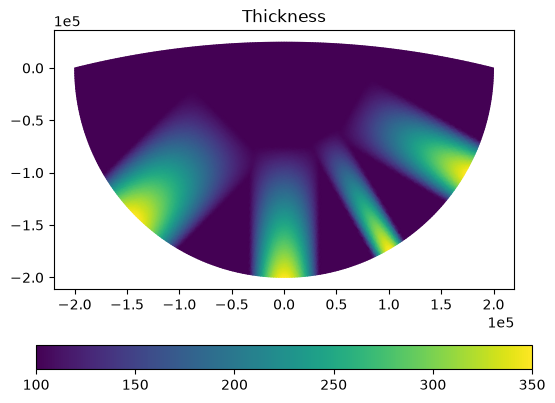

In [13]:
fig, axes = icepack.plot.subplots()
axes.set_title("Thickness")
colors = firedrake.tripcolor(h0, axes=axes)
fig.colorbar(colors, orientation="horizontal");

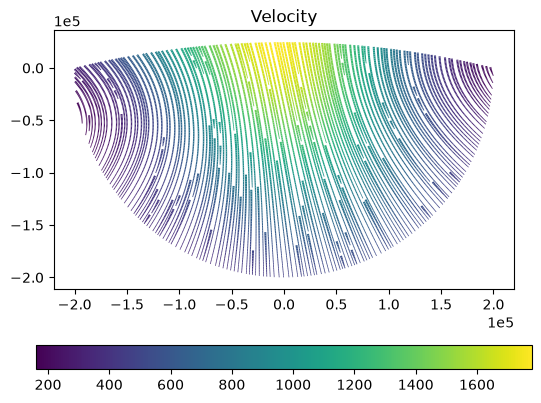

In [15]:
fig, axes = icepack.plot.subplots()
axes.set_title("Velocity")
streamlines = firedrake.streamplot(u0, seed=1729, resolution=2e3, axes=axes)
fig.colorbar(streamlines, orientation="horizontal");

## **Modelling**  
To start solving things, we need two objects. The class *IceShelf* represents what physics roblem we're interested in.  
The class *FlowSolver* decides how we're going to solve that problem. When we initialise the flow solver we pass it any arguments that never change throughout the simulation. For example, the parts of the domain boundary that we apply Dirichlet boundary conditions to stay the same, passed as *dirichlet_ids*.

In [16]:
import icepack

# Ice Shelf class
model = icepack.models.IceShelf()

# Flow solver class
solver = icepack.solvers.FlowSolver(model, dirichlet_ids=[1])

The flow solver solves the PDEs for ice velocity and thickness for which it has two methods: *diagnostic_solve* and *prognostic_solve*.  
Finally, we need the input variable *A*. Here, we use a spatially constant temperature of -18 degrees. 

In [17]:
T = firedrake.Constant(255.15)
A = icepack.rate_factor(T)

To compute the velocity field, we call the diagnostic solve method of the ice shelf object. This method takes the thickness, *A*, and the initial guess for ice velocity.

In [19]:
h = h0.copy(deepcopy=True)
u = solver.diagnostic_solve(
    velocity=u0,
    thickness=h,
    fluidity=A,
)

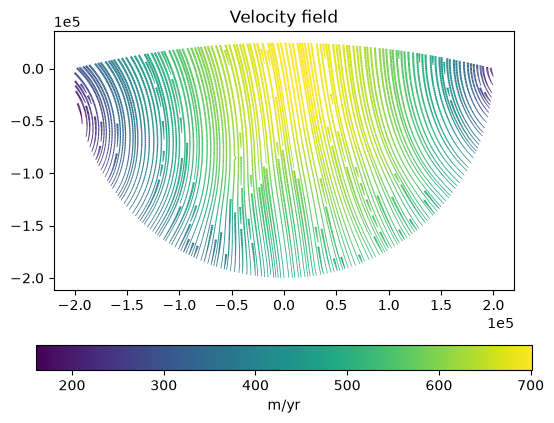

In [20]:
fig, axes = icepack.plot.subplots()
axes.set_title("Velocity field")
streamlines = firedrake.streamplot(u, seed=1729, resolution=2e3, axes=axes)
fig.colorbar(streamlines, orientation="horizontal", label="m/yr");

To project the state of the ice shelf forward in time, we use the prognostic solve method. This updates the ince thickness forward by a given timestep given the accumulation rate and velocity. We then use the diagnostic solve to update velocity and so on.  
The following code runs the model forward several years until the ice shelf is in steady state.

In [27]:
from tqdm.notebook import trange

final_time = 400.
num_timesteps = 200
dt = final_time / num_timesteps
a = firedrake.Constant(0.0)

for step in trange(num_timesteps):
    h = solver.prognostic_solve(
        dt,
        thickness=h,
        velocity=u,
        accumulation=a,
        thickness_inflow=h0,
    )

    u = solver.diagnostic_solve(
    velocity=u,
    thickness=h,
    fluidity=A,
    )

  0%|          | 0/200 [00:00<?, ?it/s]

Below is a plot of the final ice thickness and velocity. The initial thickness profile of each ice stream has extended all the way to the terminus:

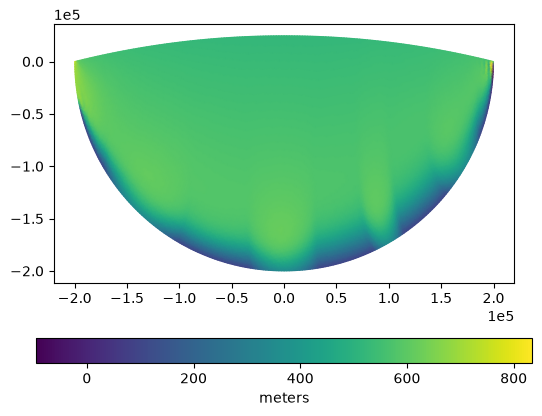

In [28]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(h, axes=axes)
fig.colorbar(colors, label="meters", orientation="horizontal");

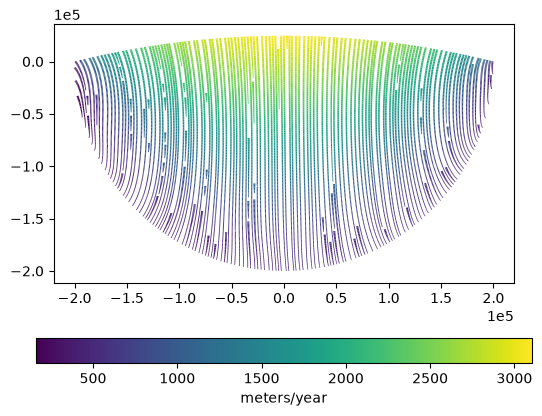

In [29]:
fig, axes = icepack.plot.subplots()
streamlines = firedrake.streamplot(u, seed=1729, resolution=2e3, axes=axes)
fig.colorbar(streamlines, label="meters/year", orientation="horizontal");

A useful quantity to know is how much ice is moving through the system. Here, we calculate total ice flux through the calving terminus:

In [30]:
from firedrake import ds

v = firedrake.FacetNormal(mesh)
flux = h * inner(u, v) * ds(2)

The extra argument to *ds* indicates we want to integrate over just the calving terminus rather than over the whole domain boundary. *flux* is a symbolic representation of this quantity; it isn't a number, but how to compute a number. The function *firedrake.assemble* evaluates the integral.

In [31]:
print(f"Flux: {firedrake.assemble(flux) / 1e9} km^3 / year")

Flux: 526.2902351992898 km^3 / year


If the system is in steady state, the flux over the inflow boundary should be the same as the accumulation rate is zero.

In [32]:
influx = -h * inner(u, v) * ds(1)
print(f"Influx: {firedrake.assemble(influx) / 1e9} km^3 / year")

Influx: 34.683035591856786 km^3 / year


They are close - the ice shelf will thicken, increasing flux at the terminus, until they equilibrate.  

## **Conclusion**  
Things to play with: change the curvature of the inflow boundary or calving terminus, change stream geometry, add a sinusoidal accumulation rate to approximate seasonal cycles. Can come back to this tutorial and add damage mechanics.